In [25]:
! pip install rdkit
! pip install pyscf
# Importa las bibliotecas necesarias
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem import Draw
from pyscf import gto, scf

In [26]:
print ('Asignale un nombre a tu molécula')
a = input()
name = str(a) + '.xyz'
name_2 = str (a) + '.molden'

Asignale un nombre a tu molécula
brevetoxin


In [27]:
print('Ahora introduce el código SMILES de tu compuesto, sin comillas:')
# Corrected SMILES for neutral Lithium Hydride
# smiles = 'COC1=C2C3=C(C(=O)CC3)C(=O)OC2=C4[C@@H]5C=CO[C@@H]5OC4=C1' #'benceno
smiles = 'C[C@@H]1C[C@H]2[C@@H](C[C@]3([C@H](O2)C[C@H]4[C@H](O3)C(=CC(=O)O4)C)C)O[C@@H]5[C@@H]1O[C@H]6C[C@@H]7[C@](C[C@@H]8[C@@](O7)(C/C=C\[C@@H]9[C@@H](O8)C[C@@H]1[C@@H](O9)C[C@@H]2[C@@](O1)([C@H](C[C@H](O2)CC(=C)C=O)O)C)C)(O[C@@]6(CC5)C)C'
print(smiles) # Print the corrected SMILES for verification

Ahora introduce el código SMILES de tu compuesto, sin comillas:
C[C@@H]1C[C@H]2[C@@H](C[C@]3([C@H](O2)C[C@H]4[C@H](O3)C(=CC(=O)O4)C)C)O[C@@H]5[C@@H]1O[C@H]6C[C@@H]7[C@](C[C@@H]8[C@@](O7)(C/C=C\[C@@H]9[C@@H](O8)C[C@@H]1[C@@H](O9)C[C@@H]2[C@@](O1)([C@H](C[C@H](O2)CC(=C)C=O)O)C)C)(O[C@@]6(CC5)C)C


<>:4: SyntaxWarning: invalid escape sequence '\['
<>:4: SyntaxWarning: invalid escape sequence '\['
/tmp/ipykernel_866/3706859178.py:4: SyntaxWarning: invalid escape sequence '\['
  smiles = 'C[C@@H]1C[C@H]2[C@@H](C[C@]3([C@H](O2)C[C@H]4[C@H](O3)C(=CC(=O)O4)C)C)O[C@@H]5[C@@H]1O[C@H]6C[C@@H]7[C@](C[C@@H]8[C@@](O7)(C/C=C\[C@@H]9[C@@H](O8)C[C@@H]1[C@@H](O9)C[C@@H]2[C@@](O1)([C@H](C[C@H](O2)CC(=C)C=O)O)C)C)(O[C@@]6(CC5)C)C'


In [28]:
mol = Chem.AllChem.MolFromSmiles(smiles) #transforma al SMILES como molécula y lo guarda en la consola

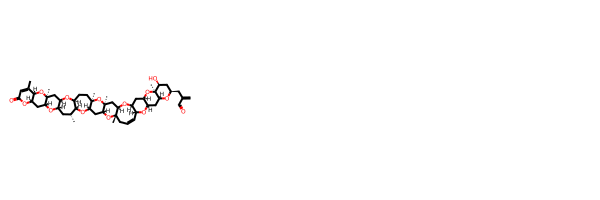

In [29]:
# Draw the strucutre
Draw.MolsToGridImage([mol])

In [30]:
mol = Chem.AddHs(mol) #agrega hidrógenos

La función Chem.MolToMolBlock(mol) pertenece a RDKit. Su objetivo es convertir una molécula representada en formato Mol (un objeto de molécula en RDKit) en un bloque de texto en formato MolBlock. El formato MolBlock es un estándar utilizado para describir estructuras moleculares en archivos de texto plano. Contiene información sobre átomos, enlaces, coordenadas y otros detalles relevantes.

In [31]:
# The current molecule has z = 0 for all atoms
# This is a 2D molecule
print(Chem.MolToMolBlock(mol))


     RDKit          2D

134144  0  0  0  0  0  0  0  0999 V2000
   -1.6852   -5.3966    0.0000 C   0  0  0  0  0  0  0  0  0  0  0  0
   -1.3515   -3.9342    0.0000 C   0  0  0  0  0  0  0  0  0  0  0  0
   -1.6852   -2.4718    0.0000 C   0  0  0  0  0  0  0  0  0  0  0  0
   -0.7500   -1.2990    0.0000 C   0  0  0  0  0  0  0  0  0  0  0  0
    0.7500   -1.2990    0.0000 C   0  0  0  0  0  0  0  0  0  0  0  0
    1.5000    0.0000    0.0000 C   0  0  0  0  0  0  0  0  0  0  0  0
    0.7500    1.2990    0.0000 C   0  0  0  0  0  0  0  0  0  0  0  0
   -0.7500    1.2990    0.0000 C   0  0  0  0  0  0  0  0  0  0  0  0
   -1.5000    0.0000    0.0000 O   0  0  0  0  0  0  0  0  0  0  0  0
   -1.5000    2.5981    0.0000 C   0  0  0  0  0  0  0  0  0  0  0  0
   -0.7500    3.8971    0.0000 C   0  0  0  0  0  0  0  0  0  0  0  0
    0.7500    3.8971    0.0000 C   0  0  0  0  0  0  0  0  0  0  0  0
    1.5000    2.5981    0.0000 O   0  0  0  0  0  0  0  0  0  0  0  0
    1.5000    5.1962    0

In [32]:
# Generate a 3D conformer for the molecule
Chem.AllChem.EmbedMolecule(mol, Chem.AllChem.ETKDGv2())

0

La función Chem.MolToMolBlock(mol) pertenece a RDKit. Su objetivo es convertir una molécula representada en formato Mol (un objeto de molécula en RDKit) en un bloque de texto en formato MolBlock. El formato MolBlock es un estándar utilizado para describir estructuras moleculares en archivos de texto plano. Contiene información sobre átomos, enlaces, coordenadas y otros detalles relevantes.

aquí podemos obsrvar que al aplicar la función embed se convierte en un objeto tridimensional

In [33]:
# The current molecule has z = 0 for all atoms
# This is a 2D molecule
print(Chem.MolToMolBlock(mol))


     RDKit          3D

134144  0  0  0  0  0  0  0  0999 V2000
   -6.0796   -2.4351    0.1254 C   0  0  0  0  0  0  0  0  0  0  0  0
   -5.3717   -1.5200    1.0908 C   0  0  2  0  0  0  0  0  0  0  0  0
   -6.2841   -0.8717    2.0746 C   0  0  0  0  0  0  0  0  0  0  0  0
   -7.4596   -0.1511    1.5384 C   0  0  1  0  0  0  0  0  0  0  0  0
   -7.2139    0.5710    0.2279 C   0  0  1  0  0  0  0  0  0  0  0  0
   -8.3113    1.6184    0.0991 C   0  0  0  0  0  0  0  0  0  0  0  0
   -9.6118    0.8043    0.0486 C   0  0  1  0  0  0  0  0  0  0  0  0
   -9.6909    0.0078    1.3327 C   0  0  2  0  0  0  0  0  0  0  0  0
   -8.6349   -0.8655    1.4594 O   0  0  0  0  0  0  0  0  0  0  0  0
  -11.0217   -0.7564    1.2941 C   0  0  0  0  0  0  0  0  0  0  0  0
  -12.0893    0.3175    1.2914 C   0  0  1  0  0  0  0  0  0  0  0  0
  -11.8895    1.1534    0.0427 C   0  0  2  0  0  0  0  0  0  0  0  0
  -10.6463    1.7319   -0.0101 O   0  0  0  0  0  0  0  0  0  0  0  0
  -12.9351    2.2013    0

Guardamos la molécula como un archivo .xyz

In [34]:
# Guardamos la molécula como un archivo .xyz
Chem.MolToXYZFile(mol, name)

La función **gto.M()** en PySCF se utiliza para definir y configurar la estructura molecular en cálculos de química cuántica.


In [35]:
# Define the molecule directly in PySCF using atom and coordinates
# Using approximate coordinates for LiH
mol = gto.M(atom=name,
   # atom='Li 0 0 0; H 0 0 1.6',  # Define atoms and approximate bond length in Angstrom
    charge=0, # Neutral molecule
    spin=0, # Singlet spin state for LiH
    unit='Angstrom' # Specify the unit for coordinates
)
mol.basis = "6-31G" # set basis set
mf = mol.KS() # set the functional
mf.xc = 'b3lyp'

# run energy calculations
energy = mf.kernel()

print(f"Calculation finished successfully. Energy: {energy} Hartree")

converged SCF energy = -2962.07544817496
Calculation finished successfully. Energy: -2962.0754481749573 Hartree


In [36]:
if mol is None:
    print("Error: Could not convert SMILES to molecule. Please check your SMILES string.")
else:
    print("SMILES successfully converted to molecule.")

SMILES successfully converted to molecule.


In [37]:
# display all the energy of molecular orbitals
mf.mo_energy

array([-18.92316501, -18.90668691, -18.90342403, -18.89313069,
       -18.89194739, -18.88938258, -18.88914833, -18.88296972,
       -18.88230346, -18.88069437, -18.87500076, -18.87449912,
       -18.86138068, -18.85998085, -10.10114583, -10.08708066,
       -10.08583997, -10.08159664, -10.07829146, -10.07613508,
       -10.07508269, -10.07402296, -10.06933544, -10.06651726,
       -10.0663181 , -10.06628938, -10.06589355, -10.06587815,
       -10.06490645, -10.064215  , -10.0634915 , -10.06321267,
       -10.06306311, -10.06001867, -10.05999905, -10.05951788,
       -10.05864459, -10.05826835, -10.03087399, -10.02951199,
       -10.02741661, -10.02383876, -10.02283928, -10.02277459,
       -10.02183675, -10.02135936, -10.02095027, -10.02068985,
       -10.0181451 , -10.01569804, -10.01529187, -10.01355545,
       -10.00594745, -10.00352775, -10.00197443, -10.00143737,
        -9.99892456,  -9.99839578,  -9.99833993,  -9.99821848,
        -9.98998204,  -9.98884147,  -9.98803809,  -9.98

In [38]:
# aquí ponemos algunos analisis de los arrays
print (mf.mo_energy.shape)
print (mf.mo_occ.shape)

print (mf.mo_occ) #la función mf.mo_occ hace referencia al número de electrones que ocupan un orbital,
###devuelve un array con el número de lectrones que ocupan el orital 2 ó 0

print (mf.mo_energy <0)
print (mf.mo_occ == 0)

(390,)
(390,)
[2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.
 2. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 

## Asignación de valores para HOMO LUMO

Aquí asignaremos los valores de orbitales HOMO y LUMO a una variable corresondiente:

Tenemos tres maneras posibles

Usando la funcíon **mf.Mo_occ**

In [39]:
#la función mf.mo_occ hace referencia al número de electrones que ocupan un orbital,
###devuelve un array con el número de lectrones que ocupan el orital 2 ó 0

homo = mf.mo_energy[mf.mo_occ > 0][-1]
lumo = mf.mo_energy[mf.mo_occ == 0][0]
print (homo)
print(lumo)

-0.1076228387785485
0.03869025542047111


Uilizando la función **mf.mo_energy**

In [40]:
homo = mf.mo_energy[mf.mo_energy < 0][-1]
lumo = mf.mo_energy[mf.mo_energy > 0][0]
print (homo)
print(lumo)

####ALERTA:

###Habria que revisar si es una ley que siempre HOMO debe ser enrgía negativa o LUMO siempre es energía positiva

-0.1076228387785485
0.03869025542047111


Utilizando la función **mol.tot_electrons**/2

In [41]:
homo = mf.mo_energy[0]
homo

np.float64(-18.923165010669877)

In [42]:
mf.mo_energy[0]

np.float64(-18.923165010669877)

In [43]:
# total number of electrons
n = mol.tot_electrons()
# HOMO is n/2 orbital. But python index starts from 0
homo = mf.mo_energy[int(n/2)-1]
# So, LUMO is the next position:
lumo = mf.mo_energy[int(n/2)]

#_________________________________________________________________________________________
# the unit of energy is Hartree. To convert to eV
#homo * 27.2114
#lumo * 27.2114

In [44]:
n

482

In [45]:
#we can print a summary with starins

print('LUMO = '+ str(lumo * 27.2114) + ' eV' + ', ó ' + f'{lumo}' + ' Hartree')
print('HOMO = '+ f'{str(homo * 27.2114)}' + ' eV' + ', ó ' + f'{homo}' + ' Hartree')
print('gap = ' + str(abs((lumo - homo)* 27.2114)) + ' eV' + ', ó ' + f'{lumo}' + ' Hartree')


LUMO = 1.0528160163486076 eV, ó 0.03869025542047111 Hartree
HOMO = -2.928568115138595 eV, ó -0.1076228387785485 Hartree
gap = 3.9813841314872023 eV, ó 0.03869025542047111 Hartree


##import definitions for molecular orbital

In [46]:
mf.mo_occ

array([2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2.,
       2., 2., 2., 2., 2.

In [47]:
# import the definitions
from pyscf.tools import molden

# we will write the surface to molden files
with open(name_2, 'w') as f1:
    molden.header(mol, f1)
    molden.orbital_coeff(mol, f1, mf.mo_coeff, ene=mf.mo_energy, occ=mf.mo_occ)

In [49]:
from google.colab import files
files.download('molecula.molden')
files.download('molecula.xyz')

FileNotFoundError: Cannot find file: molecula.molden

entonces apartir de un SMILES debe pasar a tarves de las iguientes funciones

SMILE

convertir el SMILE a molecula

agregar hidrógenos

empotrar una estructura tridimensinal, verificar con archivos molnoteblock que se haya signado

guardar archivo .xyz